# IPF GL Points — measuring relative strength in powerlifting

This notebook shows on real competition data how the **IPF GL Points** metric works, how to read its value
and — most importantly — where a single number stops being enough. The full write-up lives in `README.md`
(English) and `README.pl.md` (Polish); this notebook holds the calculations and charts it refers to.

**Data:** [OpenIPF](https://www.openipf.org/) — the subset of the OpenPowerlifting database covering
IPF-affiliated federations (drug-tested competitions). License: public domain.

**How to run:** `USE_SAMPLE = False` downloads the full dataset (~70 MB, once, into `data/raw/`).
`USE_SAMPLE = True` uses the sample bundled with the repository (results since 2024) and works offline.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from powerlifting_metrics import GL_COEFFICIENTS, IPF_WEIGHT_CLASSES, ipf_gl, ipf_gl_column, load_openipf

USE_SAMPLE = False  # True = small bundled sample (since 2024), works offline

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
pd.set_option("display.precision", 1)
SEX_LABEL = {"M": "Men", "F": "Women"}
COLORS = {"M": "#2a6fdb", "F": "#d1495b"}


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

## 1. Data

We keep only **valid full-power results** (squat + bench press + deadlift, `Event = SBD`) with a successful
total and a recorded bodyweight, from 2019 onwards — the current IPF weight classes apply since then.

In [2]:
df = load_openipf(use_sample=USE_SAMPLE)
print(f"Results: {len(df):,}   lifters: {df['Name'].nunique():,}   "
      f"period: {df['Date'].min():%Y-%m-%d} – {df['Date'].max():%Y-%m-%d}")
display(df.groupby(["Equipment", "Sex"]).size().unstack().rename(columns=SEX_LABEL))
df.head()

Results: 408,937   lifters: 163,563   period: 2019-01-05 – 2026-10-18


Sex,Women,Men
Equipment,,
Raw,125184,247929
Single-ply,12710,23114


,Name,Sex,Event,Equipment,Age,Division,BodyweightKg,WeightClassKg,Best3SquatKg,Best3BenchKg,Best3DeadliftKg,TotalKg,Place,Dots,Wilks,Goodlift,Country,Federation,Date,MeetName
0,Abigail Poche,F,SBD,Raw,13.5,FR-Y3,53.9,57,52.2,34.0,77.1,163.3,1,194.1,197.9,40.0,USA,USAPL,2019-01-05,East Regional High School Qualifier
1,Alyssa Haase,F,SBD,Single-ply,14.5,F-T1,65.9,72,90.7,45.4,88.5,224.5,1,235.1,233.2,39.5,USA,USAPL,2019-01-05,East Regional High School Qualifier
2,Amelia Day,F,SBD,Raw,15.5,FR-T2,113.3,84+,117.9,61.2,131.5,310.7,1,253.7,251.1,53.8,USA,USAPL,2019-01-05,East Regional High School Qualifier
3,Ananiesa Brantley,F,SBD,Raw,16.5,FR-T2,55.1,57,65.8,36.3,70.3,172.4,1,202.1,205.5,41.5,USA,USAPL,2019-01-05,East Regional High School Qualifier
4,Asia Peterson,F,SBD,Raw,13.5,FR-T1,90.5,84+,124.7,63.5,147.4,335.7,1,298.5,289.4,61.7,USA,USAPL,2019-01-05,East Regional High School Qualifier


## 2. The metric: IPF GL Points

IPF GL Points (*Goodlift*) is the official formula of the International Powerlifting Federation since
1 May 2020, used to pick the best lifter of a competition regardless of weight class:

$$
\mathrm{GL} = \frac{100 \cdot \mathrm{Total}}{A - B \cdot e^{-C \cdot \mathrm{BW}}}
$$

- **Total** — sum of the best successful squat, bench press and deadlift attempts [kg],
- **BW** — bodyweight at the official weigh-in [kg],
- **A, B, C** — coefficients depending on sex and equipment (Raw = *classic*, Single-ply = *equipped*).

The denominator is the **total expected from a lifter of that bodyweight at the IPF World Championships**,
so GL ≈ 100 means a result at the level of a typical World Championships finalist, and GL = 80 is 80% of that level.

In [3]:
pd.DataFrame(GL_COEFFICIENTS, index=["A", "B", "C"]).T.rename_axis(["Sex", "Equipment"])

,,A,B,C
Sex,Equipment,,,
M,Raw,1199.7,1025.2,9.2e-03
F,Raw,610.3,1045.6,3.0e-02
M,Single-ply,1236.3,1449.2,1.6e-02
F,Single-ply,758.6,949.3,2.4e-02


Our own implementation (`powerlifting_metrics.ipf_gl`) — checked against the `Goodlift` column, which
OpenPowerlifting computes independently. Differences around 0.005 come only from rounding to 2 decimals.

In [4]:
df["GL"] = ipf_gl_column(df)
diff = (df["GL"] - df["Goodlift"]).abs()
print(f"Max difference: {diff.max():.4f}   rows with difference ≤ 0.005: {(diff <= 0.0051).mean():.2%}")

Max difference: 0.0050   rows with difference ≤ 0.005: 99.93%

### Valid range of the formula

The formula is a **statistical fit, not a law of physics** — it works where there was data to calibrate it
(adult lifters at World Championships). For women the denominator $A - B e^{-C \cdot BW}$ drops to zero at
$BW = \ln(B/A)/C \approx 17.7$ kg, so very light lifters (the database contains results of children) get absurd GL values.
For men it is the other way round — very low bodyweight is penalised.

In [5]:
for sex in ["F", "M"]:
    a, b, c = GL_COEFFICIENTS[(sex, "Raw")]
    print(f"{SEX_LABEL[sex]:6s} denominator = 0 at bodyweight {np.log(b / a) / c:6.1f} kg")

display(df[df["GL"] > 135].sort_values("GL", ascending=False)
          [["Name", "Sex", "Age", "BodyweightKg", "TotalKg", "GL", "Federation"]].head())
print("Results with bodyweight < 40 kg:")
display(df[df["BodyweightKg"] < 40].groupby("Sex")["GL"].describe().rename(index=SEX_LABEL))

# The lightest IPF class (women, sub-juniors) is 43 kg — drop results below 40 kg
df = df[df["BodyweightKg"] >= 40].reset_index(drop=True)
print(f"After filtering: {len(df):,} results")

Women  denominator = 0 at bodyweight   17.7 kg
Men    denominator = 0 at bodyweight  -17.1 kg


,Name,Sex,Age,BodyweightKg,TotalKg,GL,Federation
372396,Queencess Euhanne Cruz,F,7.5,18.1,117.5,1304.4,PAP
372314,Francine Daenerys Magdangal,F,8.5,22.5,117.5,140.4,PAP


Results with bodyweight < 40 kg:


,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
Women,341.0,58.4,69.5,22.8,43.5,52.0,65.7,1304.4
Men,274.0,29.6,7.5,13.8,23.8,29.5,34.7,56.2


After filtering: 408,322 results


**Example.** Three lifters of different bodyweight — the ranking by kilograms is the reverse of the ranking by GL:

In [6]:
example = pd.DataFrame(
    [("Lifter A", "F", 57, 420), ("Lifter B", "M", 66, 600), ("Lifter C", "M", 120, 820)],
    columns=["Lifter", "Sex", "Bodyweight [kg]", "Total [kg]"],
)
example["GL"] = [ipf_gl(t, bw, s) for s, bw, t in example[["Sex", "Bodyweight [kg]", "Total [kg]"]].values]
example["Rank by Total"] = example["Total [kg]"].rank(ascending=False).astype(int)
example["Rank by GL"] = example["GL"].rank(ascending=False).astype(int)
example

,Lifter,Sex,Bodyweight [kg],Total [kg],GL,Rank by Total,Rank by GL
0,Lifter A,F,57,420,98.5,3,1
1,Lifter B,M,66,600,93.5,2,3
2,Lifter C,M,120,820,95.3,1,2


## 3. Why normalise? Total vs GL against bodyweight

Left column: the total in kilograms grows strongly with bodyweight, so the raw Total favours heavier lifters.
Right column: after converting to GL most of the dependence on bodyweight disappears — which is the whole point of the metric.

Men    Spearman correlation bodyweight ~ Total [kg]: +0.56
Men    Spearman correlation bodyweight ~ IPF GL    : +0.15
Women  Spearman correlation bodyweight ~ Total [kg]: +0.40
Women  Spearman correlation bodyweight ~ IPF GL    : -0.09


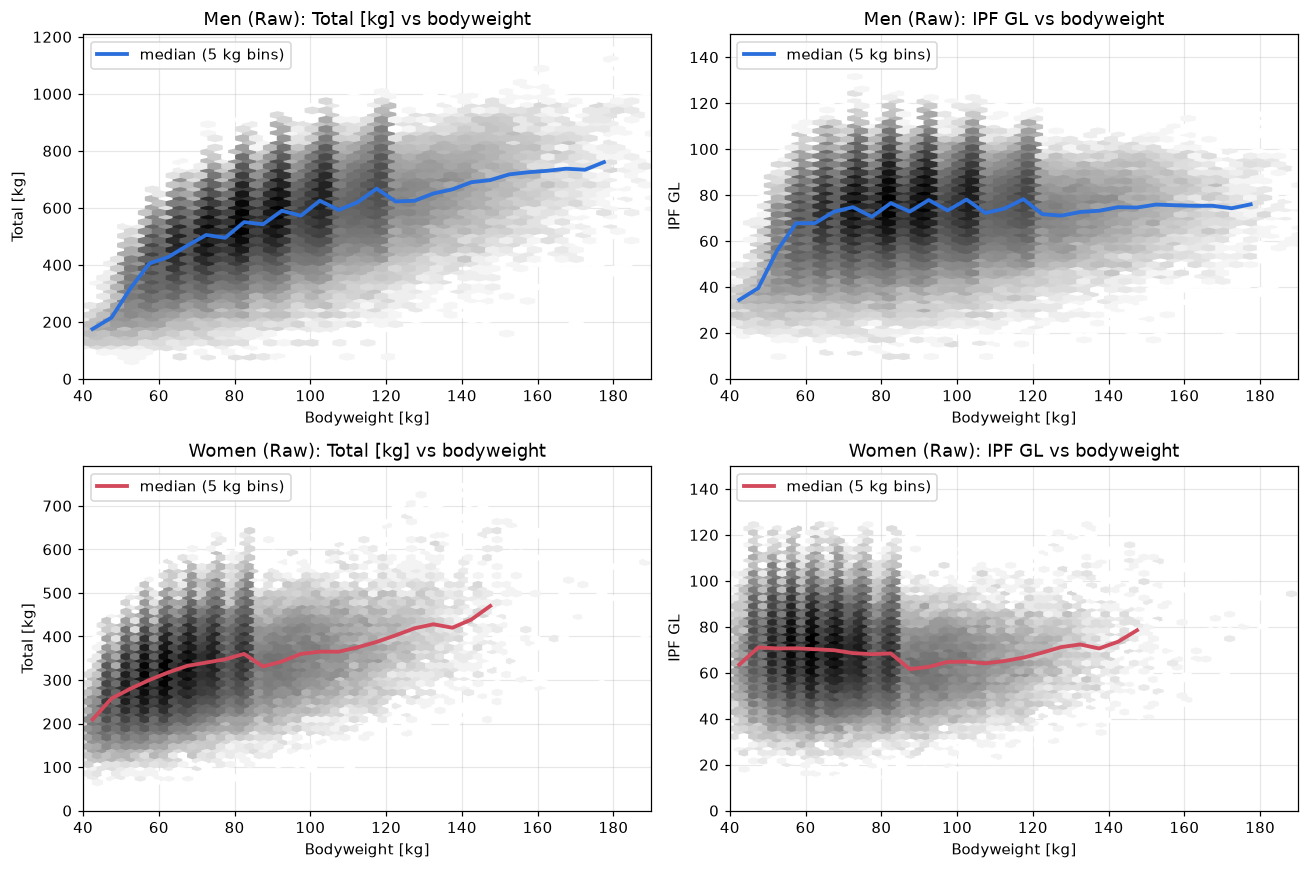

In [7]:
raw = df[df["Equipment"] == "Raw"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, sex in enumerate(["M", "F"]):
    d = raw[raw["Sex"] == sex]
    bins = pd.cut(d["BodyweightKg"], np.arange(40, 185, 5))
    for col, (metric, label) in enumerate([("TotalKg", "Total [kg]"), ("GL", "IPF GL")]):
        ax = axes[row, col]
        ax.hexbin(d["BodyweightKg"], d[metric], gridsize=60, bins="log", mincnt=1, cmap="Greys")
        med = d.groupby(bins, observed=True)[metric].agg(["median", "size"])
        med = med[med["size"] >= 100]
        ax.plot([b.mid for b in med.index], med["median"], color=COLORS[sex], lw=2.5, label="median (5 kg bins)")
        ax.set(title=f"{SEX_LABEL[sex]} (Raw): {label} vs bodyweight", xlabel="Bodyweight [kg]", ylabel=label,
               xlim=(40, 190), ylim=(0, 150) if metric == "GL" else (0, None))
        ax.legend(loc="upper left")
        print(f"{SEX_LABEL[sex]:6s} Spearman correlation bodyweight ~ {label:10s}: "
              f"{d['BodyweightKg'].corr(d[metric], method='spearman'):+.2f}")
fig.tight_layout()
save(fig, "01_total_vs_gl")

## 4. Interpretation — what does a high or low value mean?

Apart from the reference point of 100 (World Championships level), GL has no "natural" scale. To make a value
meaningful we compare it with the population: what share of results is lower? For reference — the median GL
in the Open division at the IPF World Classic Championships.

In [8]:
worlds = raw[(raw["Federation"] == "IPF")
             & (raw["MeetName"] == "World Classic Powerlifting Championships")
             & (raw["Division"] == "Open")]

pct = raw.groupby("Sex")["GL"].quantile([0.25, 0.5, 0.75, 0.9, 0.99]).unstack()
pct.columns = [f"p{int(q * 100)}" for q in pct.columns]
pct["Worlds Open median"] = worlds.groupby("Sex")["GL"].median()
display(pct.rename(index=SEX_LABEL))

thresholds = [50, 60, 70, 80, 90, 100, 110]
share_below = pd.DataFrame({SEX_LABEL[s]: [(raw.loc[raw["Sex"] == s, "GL"] < t).mean() for t in thresholds]
                            for s in ["M", "F"]}, index=[f"GL < {t}" for t in thresholds])
share_below.style.format("{:.1%}").set_caption("Share of results below a given GL value (= percentile)")

,p25,p50,p75,p90,p99,Worlds Open median
Sex,,,,,,
Women,59.7,69.1,78.8,88.2,105.7,98.5
Men,66.0,74.8,83.3,91.0,104.2,99.6


,Men,Women
GL < 50,4.6%,8.6%
GL < 60,13.7%,25.8%
GL < 70,35.5%,52.4%
GL < 80,66.0%,77.5%
GL < 90,88.6%,91.9%
GL < 100,97.6%,97.8%
GL < 110,99.7%,99.5%


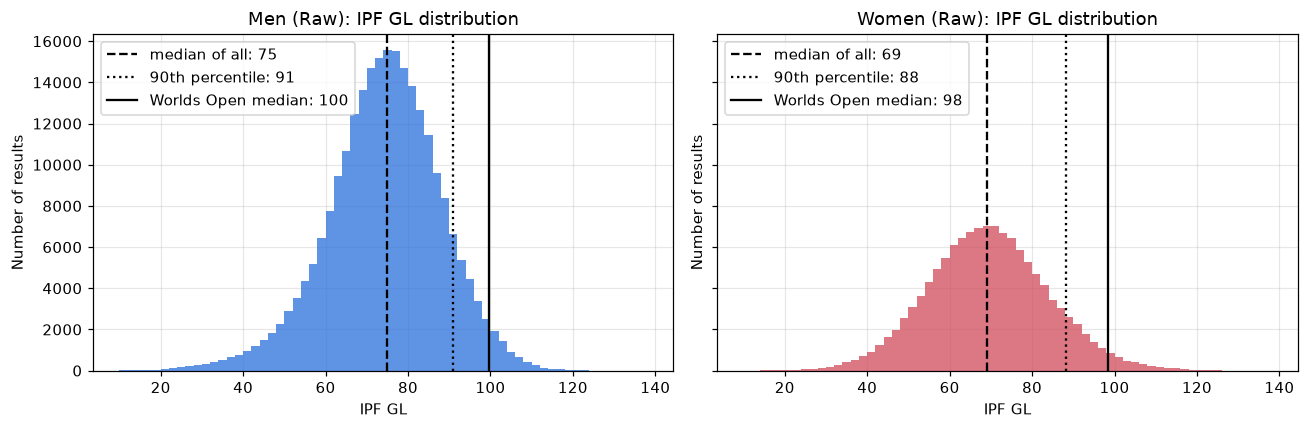

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sex in zip(axes, ["M", "F"]):
    d = raw.loc[raw["Sex"] == sex, "GL"]
    ax.hist(d, bins=np.arange(10, 140, 2), color=COLORS[sex], alpha=0.75)
    for value, label, style in [(d.median(), "median of all", "--"), (d.quantile(0.9), "90th percentile", ":"),
                                (pct.loc[sex, "Worlds Open median"], "Worlds Open median", "-")]:
        ax.axvline(value, color="black", ls=style, lw=1.5, label=f"{label}: {value:.0f}")
    ax.set(title=f"{SEX_LABEL[sex]} (Raw): IPF GL distribution", xlabel="IPF GL", ylabel="Number of results")
    ax.legend()
fig.tight_layout()
save(fig, "02_gl_distribution")

## 5. Rankings — do different metrics pick the same best lifters?

For every lifter we take their **best** result by a given metric and rank them. We compare: the raw Total,
IPF GL, and two older/alternative formulas — Wilks and DOTS.
Set `SEX` to `"F"` to repeat the analysis for women.

In [10]:
SEX = "M"
METRICS = ["TotalKg", "GL", "Dots", "Wilks"]
group = raw[raw["Sex"] == SEX].dropna(subset=METRICS)


def best_per_lifter(data, metric):
    return data.loc[data.groupby("Name")[metric].idxmax()].set_index("Name")


best = pd.DataFrame({m: best_per_lifter(group, m)[m] for m in METRICS})
ranks = best.rank(ascending=False, method="min")

top_gl = best_per_lifter(group, "GL").nlargest(10, "GL")
top_gl = top_gl[["BodyweightKg", "TotalKg", "GL", "Date", "MeetName"]].assign(
    **{f"rank by {m}": ranks.loc[top_gl.index, m].astype(int) for m in ["TotalKg", "Dots", "Wilks"]})
top_gl

,BodyweightKg,TotalKg,GL,Date,MeetName,rank by TotalKg,rank by Dots,rank by Wilks
Name,,,,,,,,
Austin Perkins #1,73.3,891.5,131.5,2026-06-13,World Classic Powerlifting Championships,217,1,1
Elliott Sykes,73.5,852.5,125.6,2026-03-05,Open Nationals,484,2,4
Joseph Borenstein,83.0,904.0,125.2,2025-10-11,Avancus Houston Primetime,164,4,6
Taylor Atwood,73.6,838.5,123.4,2021-06-14,Raw Nationals,314,5,5
Ade Omisakin,82.5,882.5,122.5,2026-06-13,World Classic Powerlifting Championships,266,6,11
William Ball #2,91.4,927.5,122.4,2026-06-13,World Classic Powerlifting Championships,89,8,14
Kjell Egil Bakkelund,65.6,782.0,122.3,2026-01-31,Sheffield Powerlifting Championships,1055,3,3
Bobb Matthews,110.8,1010.5,121.7,2025-11-22,SBD Austin,12,7,10
Anthony McNaughton,104.0,980.0,121.6,2026-06-13,World Classic Powerlifting Championships,22,9,13


In [11]:
top10 = pd.DataFrame({m: best[m].nlargest(10).index for m in METRICS}, index=range(1, 11))
top10.columns = ["Top 10 by Total", "Top 10 by GL", "Top 10 by DOTS", "Top 10 by Wilks"]
top10

,Top 10 by Total,Top 10 by GL,Top 10 by DOTS,Top 10 by Wilks
1,Jesus Olivares,Austin Perkins #1,Austin Perkins #1,Austin Perkins #1
2,Devonte Lewis #1,Elliott Sykes,Elliott Sykes,Jesus Olivares
3,Ray Williams #1,Joseph Borenstein,Kjell Egil Bakkelund,Kjell Egil Bakkelund
4,Temur Samkharadze,Taylor Atwood,Joseph Borenstein,Elliott Sykes
5,Viktor Golinei,Ade Omisakin,Taylor Atwood,Taylor Atwood
6,Ajay Sharma #1,William Ball #2,Ade Omisakin,Joseph Borenstein
7,Ray Bowring,Kjell Egil Bakkelund,Bobb Matthews,Devonte Lewis #1
8,Rondel Hunte,Bobb Matthews,William Ball #2,Temur Samkharadze
9,Cenk Koçak,Anthony McNaughton,Anthony McNaughton,Ray Williams #1
10,Jezza Uepa,Ashton Rouska,Jesus Olivares,Bobb Matthews


In [12]:
print("Spearman rank correlation (all lifters):")
display(best.corr(method="spearman").style.format("{:.3f}"))

overlap = pd.DataFrame(
    {n: {f"GL vs {m}": len(set(best["GL"].nlargest(n).index) & set(best[m].nlargest(n).index)) / n
         for m in ["TotalKg", "Dots", "Wilks"]} for n in [10, 50, 100, 1000]})
overlap.columns = [f"top {n}" for n in overlap.columns]
overlap.style.format("{:.0%}").set_caption("Overlap of top-N lists (same lifters)")

Spearman rank correlation (all lifters):


,TotalKg,GL,Dots,Wilks
TotalKg,1.000,0.886,0.862,0.854
GL,0.886,1.000,0.995,0.989
Dots,0.862,0.995,1.000,0.999
Wilks,0.854,0.989,0.999,1.000


,top 10,top 50,top 100,top 1000
GL vs TotalKg,0%,18%,21%,38%
GL vs Dots,90%,84%,82%,89%
GL vs Wilks,60%,72%,69%,81%


## 6. Limitations of the metric — checked on data

### 6.1 Does GL really level out weight classes?

If the formula were perfectly fair, the best lifters of every weight class would have similar values.
We take the mean of the 10 best results (one per lifter) in each class and divide it by the mean across all
classes (1.00 = average class). Same for Wilks and DOTS.

*Methodological note:* classes differ in size — in the most populated ones the top 10 is drawn from a larger
pool, so it is naturally stronger. Even judging whether a metric is "fair" depends on assumptions.

Men    lifters per class: {'59': 4371, '66': 10074, '74': 20177, '83': 29143, '93': 29085, '105': 20405, '120': 10254, '120+': 4935}


Women  lifters per class: {'47': 1997, '52': 4656, '57': 8298, '63': 11729, '69': 8876, '76': 7275, '84': 6997, '84+': 6266}


,Men,Women
GL,4.4%,2.0%
Dots,2.2%,2.6%
Wilks,1.2%,3.2%


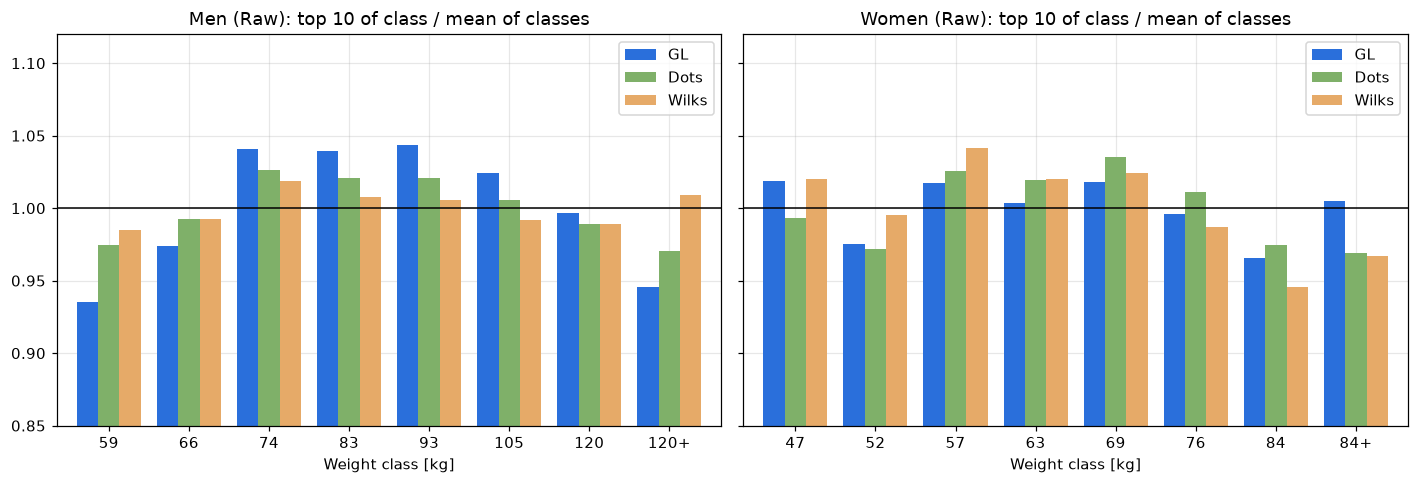

In [13]:
def top_mean_by_class(data, metric, n=10):
    return (data.loc[data.groupby("Name")[metric].idxmax()]
                .groupby("WeightClassKg")[metric].apply(lambda s: s.nlargest(n).mean()))


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
spread = {}
for ax, sex in zip(axes, ["M", "F"]):
    classes = IPF_WEIGHT_CLASSES[sex]
    d = raw[(raw["Sex"] == sex) & raw["WeightClassKg"].isin(classes)].dropna(subset=["Dots", "Wilks"])
    print(f"{SEX_LABEL[sex]:6s} lifters per class:",
          d.groupby("WeightClassKg")["Name"].nunique().loc[classes].to_dict())
    rel = pd.DataFrame({m: top_mean_by_class(d, m) for m in ["GL", "Dots", "Wilks"]}).loc[classes]
    rel = rel / rel.mean()
    spread[SEX_LABEL[sex]] = rel.std() / rel.mean()
    rel.plot.bar(ax=ax, width=0.8, color=["#2a6fdb", "#7fb069", "#e6aa68"], rot=0)
    ax.axhline(1, color="black", lw=1)
    ax.set(title=f"{SEX_LABEL[sex]} (Raw): top 10 of class / mean of classes", xlabel="Weight class [kg]",
           ylim=(0.85, 1.12))
fig.tight_layout()
save(fig, "03_weight_class_bias")
pd.DataFrame(spread).style.format("{:.1%}").set_caption("Spread between classes (coefficient of variation) — lower is more even")

### 6.2 Age

GL ignores age. The median GL by age shows how much juniors and masters are "penalised"
compared with lifters at their peak.

Men    median GL peaks at age 27: 81.7; age 18: 71.5; age 60: 63.7
Women  median GL peaks at age 25: 75.6; age 18: 66.9; age 60: 57.4


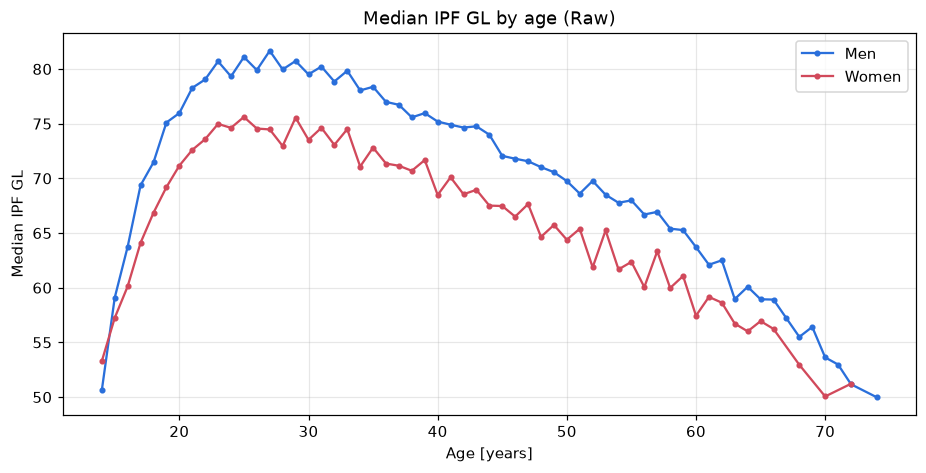

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for sex in ["M", "F"]:
    d = raw[(raw["Sex"] == sex) & raw["Age"].between(14, 75)]
    by_age = d.groupby(d["Age"].round().astype(int))["GL"].agg(["median", "size"])
    by_age = by_age[by_age["size"] >= 100]
    ax.plot(by_age.index, by_age["median"], marker="o", ms=3, color=COLORS[sex], label=SEX_LABEL[sex])
    peak = by_age["median"].idxmax()
    print(f"{SEX_LABEL[sex]:6s} median GL peaks at age {peak}: {by_age.loc[peak, 'median']:.1f}; "
          f"age 18: {by_age['median'].get(18, np.nan):.1f}; age 60: {by_age['median'].get(60, np.nan):.1f}")
ax.set(title="Median IPF GL by age (Raw)", xlabel="Age [years]", ylabel="Median IPF GL")
ax.legend()
save(fig, "04_gl_by_age")

### 6.3 Equipment (Raw vs Single-ply)

GL has separate coefficients for equipped lifting, so in theory results are comparable.
Let's check lifters who competed in both categories — are their best GL values similar?

In [15]:
both = (df.groupby(["Name", "Equipment"])["GL"].max().unstack().dropna())
both["difference (Single-ply − Raw)"] = both["Single-ply"] - both["Raw"]
print(f"Lifters who competed in both categories: {len(both):,}")
both["difference (Single-ply − Raw)"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_frame().T

Lifters who competed in both categories: 8,469


,count,mean,std,min,10%,25%,50%,75%,90%,max
difference (Single-ply − Raw),8469.0,-6.2,11.0,-69.0,-18.4,-12.9,-6.4,3.9e-02,6.1,87.4


### 6.4 Variability — one meet is not the whole story

The same lifter scores different GL at different meets (form, weight cut, missed attempts, purpose of the meet).
We look at lifters with at least 5 Raw results. On the full data (since 2019) the right-hand chart shows an
extreme case: the ranking leader has a December 2023 result with a total of 125 kg (25 / 25 / 75 kg, GL ≈ 18) —
a token total, not an attempt at a maximal result. The metric does not know why the lifter stepped on the platform.

Lifters with ≥5 results: 19,303


,count,mean,std,min,25%,50%,75%,90%,max
std,19303.0,5.1,3.2,0.3,3.0,4.4,6.4,8.7,41.3
range,19303.0,14.1,9.2,0.8,8.0,12.0,17.7,24.6,113.3


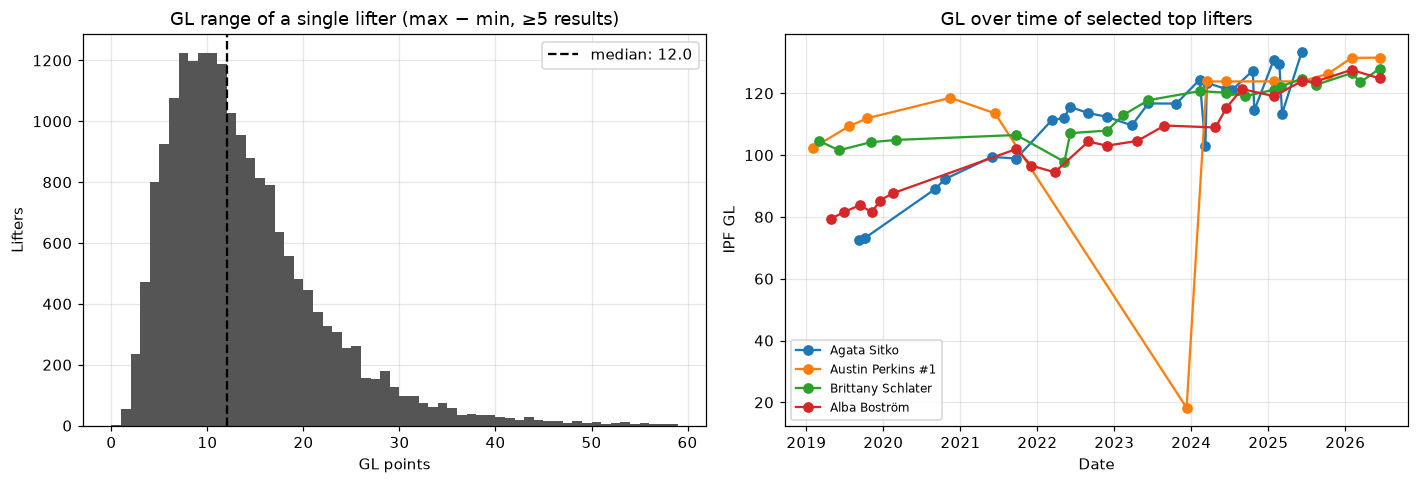

In [16]:
per_lifter = raw.groupby("Name")["GL"].agg(["size", "std", "min", "max", "median"])
regular = per_lifter[per_lifter["size"] >= 5].copy()
regular["range"] = regular["max"] - regular["min"]
print(f"Lifters with ≥5 results: {len(regular):,}")
display(regular[["std", "range"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(regular["range"], bins=np.arange(0, 60, 1), color="#555")
axes[0].axvline(regular["range"].median(), color="black", ls="--",
                label=f"median: {regular['range'].median():.1f}")
axes[0].set(title="GL range of a single lifter (max − min, ≥5 results)", xlabel="GL points", ylabel="Lifters")
axes[0].legend()

stars = regular[regular["size"] >= 8].nlargest(4, "max").index
for name in stars:
    h = raw[raw["Name"] == name].sort_values("Date")
    axes[1].plot(h["Date"], h["GL"], marker="o", label=name)
axes[1].set(title="GL over time of selected top lifters", xlabel="Date", ylabel="IPF GL")
axes[1].legend(fontsize=8)
fig.tight_layout()
save(fig, "05_gl_variability")

### 6.5 Same number, different profile

GL only looks at the total. Lifters with similar GL can have completely different strengths — for a coach
planning training or attempt selection this is key information that the metric does not carry.

In [17]:
profile = best_per_lifter(group, "GL").nlargest(10, "GL")
lifts = ["Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg"]
shares = profile[lifts].div(profile["TotalKg"], axis=0).mul(100)
shares.columns = ["% squat", "% bench", "% deadlift"]
pd.concat([profile[["BodyweightKg", "TotalKg", "GL"]], shares], axis=1)

,BodyweightKg,TotalKg,GL,% squat,% bench,% deadlift
Name,,,,,,
Austin Perkins #1,73.3,891.5,131.5,38.1,23.3,38.6
Elliott Sykes,73.5,852.5,125.6,37.8,23.2,39.0
Joseph Borenstein,83.0,904.0,125.2,34.0,24.2,41.8
Taylor Atwood,73.6,838.5,123.4,36.1,23.3,40.6
Ade Omisakin,82.5,882.5,122.5,35.4,23.2,41.4
William Ball #2,91.4,927.5,122.4,36.1,23.5,40.4
Kjell Egil Bakkelund,65.6,782.0,122.3,33.2,25.3,41.5
Bobb Matthews,110.8,1010.5,121.7,36.4,24.5,39.1
Anthony McNaughton,104.0,980.0,121.6,37.5,25.0,37.5


## 7. Who is better? Peak performance vs consistency

Among lifters with at least 5 results we compare two rankings based on **the same metric**:
the best result of their career (*peak*) and the median of all their results (*typical result*).

In [18]:
stats = (group.groupby("Name")["GL"].agg(starts="size", best="max", median="median")
              .query("starts >= 5"))
stats["rank by best"] = stats["best"].rank(ascending=False, method="min").astype(int)
stats["rank by median"] = stats["median"].rank(ascending=False, method="min").astype(int)

print("Top 10 by best result:")
display(stats.nsmallest(10, "rank by best"))
print("Top 10 by median:")
display(stats.nsmallest(10, "rank by median"))

Top 10 by best result:


,starts,best,median,rank by best,rank by median
Name,,,,,
Austin Perkins #1,13,131.5,123.8,1,1
Elliott Sykes,9,125.6,113.5,2,21
Joseph Borenstein,13,125.2,118.8,3,2
Taylor Atwood,12,123.4,116.2,4,6
Ade Omisakin,18,122.5,109.3,5,55
William Ball #2,6,122.4,113.0,6,24
Kjell Egil Bakkelund,18,122.3,113.6,7,18
Bobb Matthews,7,121.7,116.5,8,4
Anthony McNaughton,12,121.6,115.0,9,9


Top 10 by median:


,starts,best,median,rank by best,rank by median
Name,,,,,
Austin Perkins #1,13,131.5,123.8,1,1
Joseph Borenstein,13,125.2,118.8,3,2
Russel Orhii,10,120.9,117.0,13,3
Bobb Matthews,7,121.7,116.5,8,4
Ashton Rouska,18,121.0,116.3,10,5
Taylor Atwood,12,123.4,116.2,4,6
Jonathan Cayco,13,120.4,116.0,16,7
Emil Krastev,13,120.6,115.2,14,8
Anthony McNaughton,12,121.6,115.0,9,9


We look for a concrete pair from the top where "best GL" points to one lifter and "median GL" to the other —
and check whether they met at the same competitions.

In [19]:
top = stats.nsmallest(15, "rank by best")
pairs = [(a, b, top.at[b, "median"] - top.at[a, "median"])
         for a in top.index for b in top.index
         if top.at[a, "best"] > top.at[b, "best"] and top.at[a, "median"] < top.at[b, "median"]]
if not pairs:
    print("No pair in the top where the two rankings point to different lifters.")
else:
    a, b, _ = max(pairs, key=lambda p: p[2])
    display(stats.loc[[a, b]])

    meets = group[group["Name"].isin([a, b])]
    common = meets.groupby(["Date", "MeetName"]).filter(lambda m: m["Name"].nunique() == 2)
    if common.empty:
        print("These lifters did not compete at the same meet in the analysed period.")
    else:
        print("Head-to-head (GL at the same meets):")
        display(common.pivot_table(index=["Date", "MeetName"], columns="Name", values="GL"))

,starts,best,median,rank by best,rank by median
Name,,,,,
Ade Omisakin,18,122.5,109.3,5,55
Russel Orhii,10,120.9,117.0,13,3


Head-to-head (GL at the same meets):


,Name,Ade Omisakin,Russel Orhii
Date,MeetName,,
2021-09-23,World Classic Powerlifting Championships,103.9,116.7
2025-01-26,Sheffield Powerlifting Championships,118.0,120.6


## 8. Conclusions

1. **GL does what it was designed for:** it removes most of the dependence of the result on bodyweight
   and lets us compare lifters across weight classes with a single number (section 3).
2. **The value must be read against the population** — GL ≈ 100 is World Championships level, but only
   percentiles tell whether 75 is a lot or a little (section 4).
3. **Different formulas agree "on average" but not at the top** — rank correlation is very high, yet the top 10
   lists differ, and that is exactly where decisions (medals, team selection) are made (section 5).
4. **The metric has known biases and blind spots:** limited valid range of the formula (section 2),
   uneven weight classes, no age adjustment, dependence on equipment, large meet-to-meet variability,
   no information about the lift profile (section 6).
5. **The same metric can point to different "better" lifters** depending on whether we use the peak or the typical
   result (section 7) — so a single number does not unambiguously decide who is better.

Full discussion: `README.md` (English) / `README.pl.md` (Polish).